## Imports and db setup

In [1]:
import sys
from pathlib import Path
import duckdb
import zipfile
import os
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
import pandas as pd



data_dir = Path("../data").resolve()
assert data_dir.is_dir(), f"Data folder not found: {data_dir}"

con = duckdb.connect(str(data_dir / "project.duckdb"))

print("Database:", data_dir / "project.duckdb")
print(con.sql("SELECT version()").fetchall()[0][0])

Database: C:\Users\marks\.workspace\projects\data4600-project\code\data\project.duckdb
v2.0.0


## Add AK-2025 data to DB

In [2]:
STATES = (
    "AZ CA CO DC FL GA IL IN KS LA MD MA MI MN MO "
    "NV NJ NY NC OH PA SC TN TX WA WI"
).split()

tables = [
    ("NIBRS_incident.csv", "incident"),
    ("agencies.csv", "agencies"),
    ("NIBRS_OFFENSE.csv", "offense"),
    ("NIBRS_OFFENDER.csv", "offender"),
    ("NIBRS_VICTIM.csv", "victim"),
    ("NIBRS_VICTIM_OFFENSE.csv", "victim_offense"),
    ("NIBRS_VICTIM_OFFENDER_REL.csv", "victim_offender_rel")
]

log = []

def table_exists(table_name):
    return con.sql(f"""
        SELECT count(*) FROM information_schema.tables
        WHERE table_name = '{table_name}'
    """).fetchall()[0][0] > 0

def csv_source(csv_path, encoding):
    return f"read_csv('{csv_path}', all_varchar=true, encoding='{encoding}')"

def add_missing_columns(table_name, csv_path, encoding):
    csv_cols = [r[0] for r in con.sql(f"DESCRIBE SELECT * FROM {csv_source(csv_path, encoding)}").fetchall()]
    table_cols = {r[0].lower() for r in con.sql(f"DESCRIBE {table_name}").fetchall()}
    for col in csv_cols:
        if col.lower() not in table_cols:
            con.sql(f'ALTER TABLE {table_name} ADD COLUMN "{col}" VARCHAR')
            print(f"  added column {table_name}.{col}")

def load_csv(state, year, table_name, csv_path, encoding):
    src = csv_source(csv_path, encoding)
    con.sql(f"""
        CREATE TABLE IF NOT EXISTS {table_name} AS
        SELECT *, '{state}' AS source_state, {year} AS source_year
        FROM {src}
        LIMIT 0
    """)
    add_missing_columns(table_name, csv_path, encoding)
    con.sql(f"""
        DELETE FROM {table_name}
        WHERE source_state = '{state}' AND source_year = {year}
    """)
    con.sql(f"""
        INSERT INTO {table_name} BY NAME
        SELECT *, '{state}' AS source_state, {year} AS source_year
        FROM {src}
    """)
    db_rows = con.sql(f"""
        SELECT count(*) FROM {table_name}
        WHERE source_state = '{state}' AND source_year = {year}
    """).fetchall()[0][0]
    csv_rows = con.sql(f"SELECT count(*) FROM {src}").fetchall()[0][0]
    assert db_rows == csv_rows, f"table {db_rows}, CSV {csv_rows}"
    return db_rows

def load_state_year(state, year, reload=False):
    zip_path = data_dir / "nibrs" / str(year) / f"{state}-{year}.zip"
    extracted_path = data_dir / "extracted" / str(year) / state

    if not zip_path.exists():
        log.append({"state": state, "year": year, "table": None, "rows": None,
                    "status": "zip missing", "encoding": None, "error": None})
        print(f"{state}-{year}: zip missing")
        return

    with zipfile.ZipFile(zip_path) as zipped:
        for csv_name, table_name in tables:
            entry = {"state": state, "year": year, "table": table_name, "rows": None,
                     "status": None, "encoding": None, "error": None}
            try:
                matches = [
                    name for name in zipped.namelist()
                    if name.split("/")[-1].lower() == csv_name.lower()
                ]
                if not matches:
                    entry["status"] = "csv missing"
                    continue

                if not reload and table_exists(table_name):
                    already = con.sql(f"""
                        SELECT count(*) FROM {table_name}
                        WHERE source_state = '{state}' AND source_year = {year}
                    """).fetchall()[0][0]
                    if already > 0:
                        entry["status"], entry["rows"] = "skipped", already
                        continue

                csv_path = zipped.extract(matches[0], extracted_path)

                try:
                    entry["encoding"] = "utf-8"
                    db_rows = load_csv(state, year, table_name, csv_path, "utf-8")
                except duckdb.InvalidInputException:
                    entry["encoding"] = "latin-1"
                    db_rows = load_csv(state, year, table_name, csv_path, "latin-1")

                entry["status"] = "loaded" if db_rows else "empty"
                entry["rows"] = db_rows
                os.remove(csv_path)
            except Exception as e:
                entry["status"], entry["error"] = "failed", str(e)[:300]
            finally:
                log.append(entry)
                print(f"{state}-{year} {table_name}: {entry['status']} {entry['rows'] or ''} {entry['encoding'] or ''}")


In [3]:
for year in range(2025, 2015, -1):        # 2025 back to 2016
    for state in STATES:
        load_state_year(state, year)

log_df = pd.DataFrame(log)
con.sql("CREATE OR REPLACE TABLE load_log AS SELECT * FROM log_df")
log_df["status"].value_counts()

AZ-2025 incident: skipped 225182 
AZ-2025 agencies: skipped 95 
AZ-2025 offense: skipped 262933 
AZ-2025 offender: skipped 252851 
AZ-2025 victim: skipped 259574 
AZ-2025 victim_offense: skipped 287365 
AZ-2025 victim_offender_rel: skipped 128257 
CA-2025 incident: skipped 1254218 
CA-2025 agencies: skipped 727 
CA-2025 offense: skipped 1437518 
CA-2025 offender: skipped 1415485 
CA-2025 victim: skipped 1423295 
CA-2025 victim_offense: skipped 1560107 
CA-2025 victim_offender_rel: skipped 703987 
CO-2025 incident: skipped 260947 
CO-2025 agencies: skipped 229 
CO-2025 offense: skipped 302758 
CO-2025 offender: skipped 294159 
CO-2025 victim: skipped 298669 
CO-2025 victim_offense: skipped 332463 
CO-2025 victim_offender_rel: skipped 138647 
DC-2025 incident: skipped 58541 
DC-2025 agencies: skipped 2 
DC-2025 offense: skipped 67511 
DC-2025 offender: skipped 69346 
DC-2025 victim: skipped 67665 
DC-2025 victim_offense: skipped 74091 
DC-2025 victim_offender_rel: skipped 41742 
FL-2025 

status
skipped        1606
zip missing      28
empty            18
Name: count, dtype: int64

In [4]:
# 2016-2018 agencies files list some agencies twice in the same year,
# identical except participated = Y/N. Keep the Y row; if both match,
# keep the row with officer counts.
before = con.sql("SELECT count(*) FROM agencies").fetchall()[0][0]

con.sql("""
    CREATE OR REPLACE TABLE agencies AS
    SELECT *
    FROM agencies
    QUALIFY row_number() OVER (
        PARTITION BY agency_id, source_state, source_year
        ORDER BY (participated = 'Y') DESC NULLS LAST,
                 try_cast(male_officer AS INTEGER) DESC NULLS LAST
    ) = 1
""")

after = con.sql("SELECT count(*) FROM agencies").fetchall()[0][0]
print(f"agencies: {before} -> {after} rows ({before - after} duplicates removed)")


agencies: 68993 -> 68993 rows (0 duplicates removed)


## Add lookup tables to db

In [5]:
lookup_state = "AZ"

lookup_tables = [
    # (csv name, table name, source year)
    ("NIBRS_OFFENSE_TYPE.csv", "offense_type", 2020),   # 2020 has offense_type_id AND offense_code, all 86 codes
    ("NIBRS_RELATIONSHIP.csv", "relationship", 2025),   # 2025 has all 30 (adds 28-30)
    ("NIBRS_VICTIM_TYPE.csv", "victim_type", 2025),     # same in every year
]

for csv_name, table_name, lookup_year in lookup_tables:
    zip_path = data_dir / "nibrs" / str(lookup_year) / f"{lookup_state}-{lookup_year}.zip"
    extracted_path = data_dir / "extracted" / str(lookup_year) / lookup_state
    with zipfile.ZipFile(zip_path) as zipped:
        matches = [
            name for name in zipped.namelist()
            if name.split("/")[-1].lower() == csv_name.lower()
        ]
        csv_path = zipped.extract(matches[0], extracted_path)
    con.sql(f"""
        CREATE OR REPLACE TABLE {table_name} AS
        SELECT *
        FROM read_csv('{csv_path}', all_varchar=true)
    """)
    db_rows = con.sql(f"SELECT count(*) FROM {table_name}").fetchall()[0][0]
    csv_rows = con.sql(f"SELECT count(*) FROM read_csv('{csv_path}', all_varchar=true)").fetchall()[0][0]
    assert db_rows == csv_rows, f"{table_name}: table {db_rows}, CSV {csv_rows}"
    print(f"{table_name} (from {lookup_state}-{lookup_year}): {db_rows} rows")


offense_type (from AZ-2020): 86 rows
relationship (from AZ-2025): 30 rows
victim_type (from AZ-2025): 9 rows


## Duplicate checks

In [6]:
dupe_checks = [
    ("incident", "incident_id"),
    ("agencies", "agency_id, source_state, source_year"),
    ("offense", "offense_id"),
    ("offender", "offender_id"),
    ("victim", "victim_id"),
    ("victim_offense", "victim_id, offense_id"),
    ("victim_offender_rel", "victim_id, offender_id"),
]

for table_name, key in dupe_checks:
    dupes = con.sql(f"""
        SELECT {key}, count(*)
        FROM {table_name}
        GROUP BY {key}
        HAVING count(*) > 1
    """).fetchall()
    assert dupes == [], f"{table_name}: duplicate {key}: {dupes[:5]}"
    print(f"{table_name}: no duplicate {key}")


incident: no duplicate incident_id
agencies: no duplicate agency_id, source_state, source_year
offense: no duplicate offense_id
offender: no duplicate offender_id
victim: no duplicate victim_id
victim_offense: no duplicate victim_id, offense_id
victim_offender_rel: no duplicate victim_id, offender_id


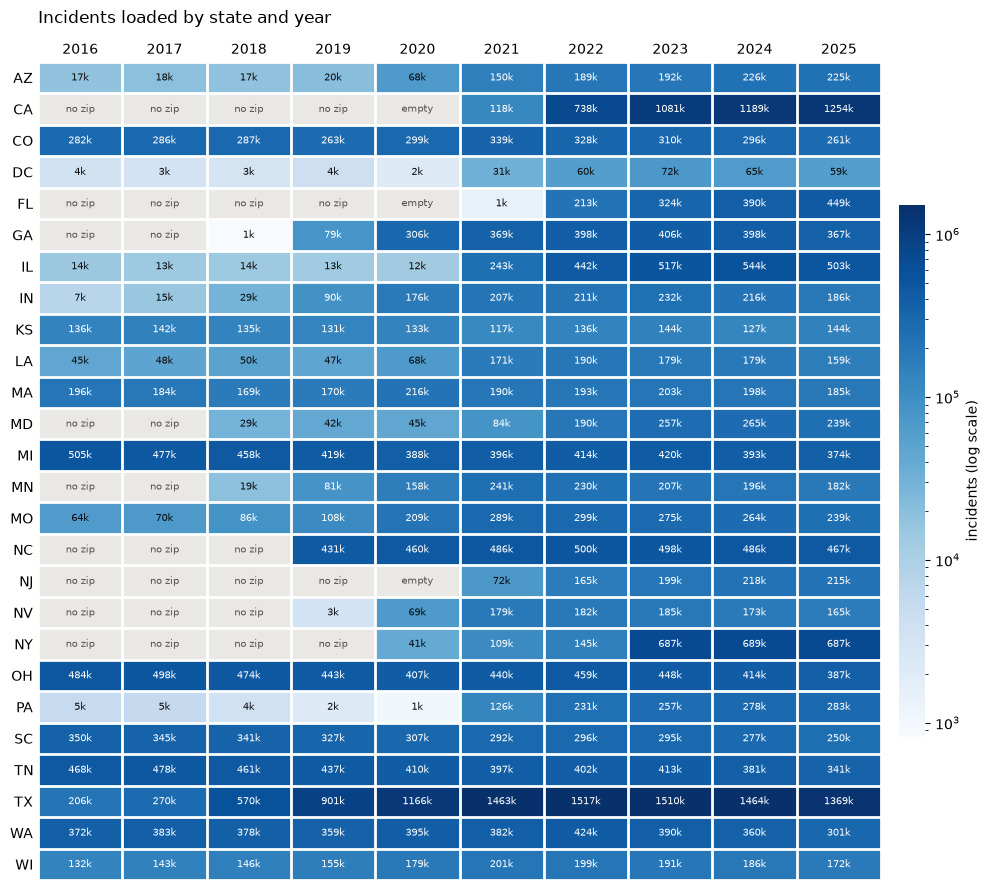

In [ ]:
# Sanity check
years = list(range(2016, 2026))
states = sorted(STATES)

counts = con.sql("""
    SELECT source_state AS state, source_year AS year, count(*) AS incidents
    FROM incident
    GROUP BY ALL
""").df()
grid = counts.pivot(index="state", columns="year", values="incidents").reindex(index=states, columns=years)

# why a cell is blank: zip missing, or header-only incident table
status = con.sql("""
    SELECT state, year, any_value(status) AS status
    FROM load_log
    WHERE status IN ('zip missing', 'empty')
      AND ("table" IS NULL OR "table" = 'incident')
    GROUP BY ALL
""").df()
blank_label = {(r.state, r.year): ("no zip" if r.status == "zip missing" else "empty")
               for r in status.itertuples()}

values = grid.values.astype(float)
cmap = plt.get_cmap("Blues").copy()
cmap.set_bad("#e9e8e4")
norm = mcolors.LogNorm(vmin=np.nanmin(values), vmax=np.nanmax(values))

fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(np.ma.masked_invalid(values), cmap=cmap, norm=norm, aspect="auto")

for i, state in enumerate(states):
    for j, year in enumerate(years):
        v = values[i, j]
        if np.isnan(v):
            ax.text(j, i, blank_label.get((state, year), "-"), ha="center", va="center",
                    fontsize=7, color="#52514e")
        else:
            ax.text(j, i, f"{v/1000:.0f}k", ha="center", va="center", fontsize=7,
                    color="white" if norm(v) > 0.6 else "#0b0b0b")

ax.set_xticks(range(len(years)), years)
ax.set_yticks(range(len(states)), states)
ax.set_xticks(np.arange(-0.5, len(years)), minor=True)
ax.set_yticks(np.arange(-0.5, len(states)), minor=True)
ax.grid(which="minor", color="white", linewidth=2)
ax.tick_params(which="both", length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.xaxis.tick_top()

cbar = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
cbar.set_label("incidents (log scale)")
cbar.outline.set_visible(False)

ax.set_title("Incidents loaded by state and year", loc="left", pad=28)
plt.tight_layout()
plt.show()

## Join checks

In [8]:
same_source = "AND c.source_state = p.source_state AND c.source_year = p.source_year"

join_checks = [
    # (child table, column, parent table, column, also match state/year?)
    ("offender", "incident_id", "incident", "incident_id", True),
    ("victim", "incident_id", "incident", "incident_id", True),
    ("offense", "incident_id", "incident", "incident_id", True),
    ("incident", "agency_id", "agencies", "agency_id", True),
    ("victim_offense", "victim_id", "victim", "victim_id", True),
    ("victim_offense", "offense_id", "offense", "offense_id", True),
    ("victim_offender_rel", "victim_id", "victim", "victim_id", True),
    ("victim_offender_rel", "offender_id", "offender", "offender_id", True),
    ("offense", "offense_code", "offense_type", "offense_code", False),
    ("offense", "offense_type_id", "offense_type", "offense_type_id", False),
    ("victim", "victim_type_id", "victim_type", "victim_type_id", False),
    ("victim_offender_rel", "relationship_id", "relationship", "relationship_id", False),
]

# Gaps in the FBI source files (row counts match the CSVs). Warn, don't stop.
known_gaps = {
    ("incident", "agency_id"): "agency not in agencies.csv",
    ("offender", "incident_id"): "2017 offenders whose incident is not in the incident file",
    ("victim_offender_rel", "offender_id"): "2017 relationships whose offender is not in the offender file",
}

for child, child_col, parent, parent_col, match_source in join_checks:
    extra = same_source if match_source else ""
    orphans = con.sql(f"""
        SELECT count(*)
        FROM {child} c
        LEFT JOIN {parent} p
            ON c.{child_col} = p.{parent_col} {extra}
        WHERE c.{child_col} IS NOT NULL
            AND p.{parent_col} IS NULL
    """).fetchall()[0][0]

    if orphans and (child, child_col) in known_gaps:
        print(f"{child}.{child_col} -> {parent}: {orphans} rows, known gap: {known_gaps[(child, child_col)]}")
        continue
    assert orphans == 0, f"{child}.{child_col}: {orphans} rows not found in {parent}"
    print(f"{child}.{child_col} -> {parent}: ok")


offender.incident_id -> incident: 17207 rows, known gap: 2017 offenders whose incident is not in the incident file
victim.incident_id -> incident: ok
offense.incident_id -> incident: ok
incident.agency_id -> agencies: 15995 rows, known gap: agency not in agencies.csv
victim_offense.victim_id -> victim: ok
victim_offense.offense_id -> offense: ok
victim_offender_rel.victim_id -> victim: ok
victim_offender_rel.offender_id -> offender: 5003 rows, known gap: 2017 relationships whose offender is not in the offender file
offense.offense_code -> offense_type: ok
offense.offense_type_id -> offense_type: ok
victim.victim_type_id -> victim_type: ok
victim_offender_rel.relationship_id -> relationship: ok


## Load NFL data

In [ ]:
nfl_path = data_dir / "nfl" / "games.csv"

con.sql(f"""
    CREATE OR REPLACE TABLE games AS
    SELECT * FROM read_csv('{nfl_path}')
""")

db_rows = con.sql("SELECT count(*) FROM games").fetchall()[0][0]
print(f"games: {db_rows} rows")

games: 7548 rows
